# 05b · Deep learning comparison: do LSTMs beat XGBoost on this data?

**Question a reviewer will ask:** traffic is a time series — why not an LSTM?
So far: MLP 0.914 (window features), 1D-CNN 0.629 (packet events), XGBoost 0.929 (window features + 3-window rolling memory).

Two recurrent models, same split (`split_run`), same metrics, 3 seeds, sqrt class weights (as XGBoost):

| Part | Model | Input | Compared with |
|---|---|---|---|
| A | **LSTM / GRU over window history** | each host's last N windows (27 base features + time gap), N = 1 / 3 / 10 | XGBoost with no memory, with 3-window rolling (our model), with 10-window rolling |
| B | **BiLSTM over packet events** | 32-event sequences (3 channels, embedded), deduplicated for training | XGBoost on the **same** test windows (sequence probabilities averaged per window) |
| C | **Late fusion** | XGBoost + best LSTM, weight tuned on val | best single model |
| D | CPU latency per 1,000 windows | | |

N = 1 is the control (an LSTM that sees no history). If N = 10 does not beat N = 1, history is not what the LSTM is good at here.

Needs `pip install torch` (CPU build is fine). Logged to MLflow, experiment **vitalgate-detection**, `tags.stage = "dl_ablation"`. Runtime ≈ 30–60 min; `FAST = True` ≈ 10 min.

In [1]:
# 0 · Setup
import os, sys, json, time, copy, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, QuantileTransformer
from sklearn.metrics import f1_score, matthews_corrcoef, average_precision_score
import xgboost as xgb
import torch
import torch.nn as nn
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

FAST = False
SEEDS = [0] if FAST else [0, 1, 2]
PKT_SEEDS = [0]                                  # packet BiLSTM is the slowest part: one seed
PKT_TRAIN_CAP = 40_000 if FAST else 150_000      # training sequences after dedup
torch.set_num_threads(os.cpu_count() or 4)
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS = REPO / "data" / "processed", REPO / "models"
REP = REPO / "reports" / "dl_ablation"; REP.mkdir(parents=True, exist_ok=True)
RAW = Path(os.environ.get("VITALGATE_DATA", REPO / "data" / "raw"))     # for sequences.npz
sys.path.insert(0, str(REPO / "src"))
import tracking, mlflow
tracking.use_experiment("vitalgate-detection")
print("torch", torch.__version__, "| xgboost", xgb.__version__, "| session", tracking.SESSION)

torch 2.15.0+cpu | xgboost 3.4.1 | session 20261114-145908


## 1 · Data, metrics, helpers

In [2]:
CFG = json.loads((MODELS / "xgb_config.json").read_text(encoding="utf-8"))
SCHEMA = json.loads((PROC / "feature_schema.json").read_text(encoding="utf-8"))
FEATURES, BEST = CFG["features"], CFG["best_params"]
BASE27 = SCHEMA["ML_23_MS"] + SCHEMA["RATIO_FEATS"]                        # no rolling: the LSTM must learn memory itself
ROLL_BASE = CFG["rolling"]["base"]
RULE_CLASS = CFG["rule_class"]
win = pd.read_parquet(PROC / "windows_v2.parquet")
d = win[win["label_class"] != RULE_CLASS].reset_index(drop=True)

def add_rolling(frame, n, suffix, stats=("mean",)):
    f = frame.sort_values(["split_run", "client_ip", "window_start"]).copy()
    g = f.groupby(["split_run", "client_ip"], sort=False)
    cols = []
    for b in ROLL_BASE:
        for st in stats:
            c = f"{b}_{suffix}_{st}"; cols.append(c)
            f[c] = g[b].transform(lambda s: getattr(s.rolling(n, min_periods=1), st)())
    return f.sort_index(), cols
d, R10 = add_rolling(d, 10, "roll10", ("mean", "max"))

le = LabelEncoder().fit(d["label_class"]); CLS = list(le.classes_); K = len(CLS)
BEN, REC = CLS.index("benign"), CLS.index("recon")
y = le.transform(d["label_class"])
TR, VA, TE = [(d["split_run"] == p).values for p in ("train", "val", "test")]
CNT = np.bincount(y[TR], minlength=K); CLASS_W = (CNT.max() / np.maximum(CNT, 1)) ** 0.5

def hours(frame, cap=60.0):
    t = frame.sort_values(["client_ip", "window_start"])
    return t.groupby("client_ip")["window_start"].diff().fillna(2.0).clip(upper=cap).sum() / 3600.0

def metrics(yt, prob, h):
    pred = prob.argmax(1); keep = yt != REC; pc = f1_score(yt, pred, labels=range(K), average=None, zero_division=0)
    return dict(macro_F1=f1_score(yt, pred, labels=range(K), average="macro", zero_division=0),
                macro_F1_no_recon=f1_score(yt[keep], pred[keep], labels=[i for i in range(K) if i != REC], average="macro", zero_division=0),
                MCC=matthews_corrcoef(yt, pred), PR_AUC=average_precision_score((yt != BEN).astype(int), 1 - prob[:, BEN]),
                F1_exfiltration=pc[CLS.index("exfiltration")], F1_ransomware_like=pc[CLS.index("ransomware_like")],
                FP_per_wallclock_h=((pred != BEN) & (yt == BEN)).sum() / h)
H_TE = hours(d[TE])
SHOW = ["macro_F1", "macro_F1_no_recon", "F1_exfiltration", "F1_ransomware_like", "FP_per_wallclock_h"]

def fit_xgb(Xa, ya, Xv, yv, seed):
    m = xgb.XGBClassifier(n_estimators=2000, max_depth=int(BEST["depth"]), learning_rate=float(BEST["lr"]), subsample=0.8,
                          colsample_bytree=0.8, tree_method="hist", objective="multi:softprob", eval_metric="mlogloss",
                          early_stopping_rounds=50, random_state=seed, n_jobs=-1)
    w = CLASS_W[ya] if BEST.get("weights") == "sqrt" else None
    return m.fit(Xa, ya, sample_weight=w, eval_set=[(Xv, yv)], verbose=False)

def summarise(rows, by="model"):
    df = pd.DataFrame(rows); g = df.groupby(by, sort=False)[SHOW + ["train_s", "ms_per_1k"]]
    return g.mean().round(3).astype(str) + " ± " + g.std().fillna(0).round(3).astype(str)
print(len(BASE27), "base features |", K, "classes | train/val/test", TR.sum(), VA.sum(), TE.sum())

27 base features | 7 classes | train/val/test 37259 5681 7898


## 2 · Torch training helpers
Adam, class-weighted cross-entropy (same √ weights as XGBoost), early stopping on **val macro-F1** (patience 3), best epoch restored.

In [3]:
def to_t(a, dtype=torch.float32): return torch.as_tensor(np.asarray(a), dtype=dtype)

def predict_torch(model, data, bs=4096):
    model.eval(); out = []
    with torch.no_grad():
        for s in range(0, len(data[0]), bs):
            out.append(torch.softmax(model(*[t[s:s + bs] for t in data]), dim=1).numpy())
    return np.concatenate(out)

def fit_torch(make_model, train, val, y_tr, y_va, seed, max_epochs, patience=3, bs=512, lr=1e-3):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    lossf = nn.CrossEntropyLoss(weight=to_t(CLASS_W))
    yt = to_t(y_tr, torch.long); n = len(y_tr)
    best_f1, best_state, best_ep, since = -1.0, None, 0, 0
    for ep in range(1, max_epochs + 1):
        model.train(); perm = rng.permutation(n)
        for s in range(0, n, bs):
            idx = torch.as_tensor(perm[s:s + bs])
            loss = lossf(model(*[t[idx] for t in train]), yt[idx])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
        f1 = f1_score(y_va, predict_torch(model, val).argmax(1), average="macro")
        if mlflow.active_run(): tracking.log_metrics({"val_macro_F1": f1}, step=ep)
        if f1 > best_f1 + 1e-4: best_f1, best_state, best_ep, since = f1, copy.deepcopy(model.state_dict()), ep, 0
        else:
            since += 1
            if since >= patience: break
    model.load_state_dict(best_state)
    return model, best_f1, best_ep

def n_params(model): return sum(p.numel() for p in model.parameters())

## 3 · Part A: window-history sequences
For each window: the same host's last N windows **inside the same split partition** (no leakage across train/val/test), oldest first, current window last, plus log(1 + gap in seconds) as a feature — windows are irregular in time. Features are quantile-scaled with statistics from train only.

In [4]:
qt = QuantileTransformer(output_distribution="normal", random_state=0).fit(d.loc[TR, BASE27])
Z = qt.transform(d[BASE27]).astype(np.float32)

def build_window_sequences(N):
    f = d[["split_run", "client_ip", "window_start"]].copy(); f["row"] = np.arange(len(f))
    f = f.sort_values(["split_run", "client_ip", "window_start"])
    g = f.groupby(["split_run", "client_ip"], sort=False)
    pos = g.cumcount().to_numpy(); gap = g["window_start"].diff().fillna(0).clip(0, 3600).to_numpy()
    rows = f["row"].to_numpy()
    feats = np.column_stack([Z[rows], (np.log1p(gap) / 8.0).astype(np.float32)])     # sorted order
    n, D = feats.shape
    S = np.zeros((n, N, D), np.float32); L = np.minimum(pos + 1, N)
    for k in range(N):                                   # k steps back from the current window
        ok = pos >= k
        r = np.where(ok)[0]
        S[r, L[r] - 1 - k] = feats[r - k]
    S_out = np.empty_like(S); L_out = np.empty_like(L)
    S_out[rows] = S; L_out[rows] = L                     # back to the row order of d
    return S_out, L_out.astype(np.int64)

class WindowRNN(nn.Module):
    def __init__(self, d_in, cell="lstm", hidden=64):
        super().__init__()
        self.rnn = (nn.LSTM if cell == "lstm" else nn.GRU)(d_in, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, K))
    def forward(self, x, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        h = h[0] if isinstance(h, tuple) else h
        return self.head(h[-1])

In [5]:
A_rows, PROBS = [], {}
# XGBoost comparators: no memory / 3-window rolling (our model) / 10-window rolling (same memory length as the LSTM)
XGB_SETS = {"XGBoost · no memory (27)": BASE27, "XGBoost · roll3 (ours, 32)": FEATURES, "XGBoost · roll10 (27+10)": BASE27 + R10}
for name, cols in XGB_SETS.items():
    with tracking.run(name, params={"n_features": len(cols), "memory": name.split("·")[1].strip()}, tags={"stage": "dl_ablation", "part": "A"}):
        pv, ps = [], []
        for s in SEEDS:
            t0 = time.time(); m = fit_xgb(d.loc[TR, cols], y[TR], d.loc[VA, cols], y[VA], s); tr_s = time.time() - t0
            t0 = time.time(); p = m.predict_proba(d.loc[TE, cols]); ms = (time.time() - t0) / TE.sum() * 1000 * 1000
            r = metrics(y[TE], p, H_TE); ps.append(p); pv.append(m.predict_proba(d.loc[VA, cols]))
            A_rows.append(dict(model=name, seed=s, train_s=tr_s, ms_per_1k=ms, **r))
        tracking.log_seed_summary([{k: v for k, v in a.items() if k not in ("model", "seed")} for a in A_rows if a["model"] == name])
        PROBS[name] = (np.mean(pv, 0), np.mean(ps, 0))
    print(name, "done")

RNN_CFGS = [("LSTM", 1), ("LSTM", 3), ("LSTM", 10), ("GRU", 10)]
for cell, N in RNN_CFGS:
    S, L = build_window_sequences(N); D = S.shape[2]
    tr, va, te = (to_t(S[TR]), to_t(L[TR], torch.long)), (to_t(S[VA]), to_t(L[VA], torch.long)), (to_t(S[TE]), to_t(L[TE], torch.long))
    name = f"{cell} · window history N={N}"
    with tracking.run(name, params={"cell": cell, "N": N, "hidden": 64, "input_dim": D}, tags={"stage": "dl_ablation", "part": "A"}):
        pv, pt = [], []
        for s in SEEDS:
            t0 = time.time()
            model, vf1, ep = fit_torch(lambda: WindowRNN(D, cell.lower()), tr, va, y[TR], y[VA], s, max_epochs=10 if FAST else 30)
            tr_s = time.time() - t0
            t0 = time.time(); p = predict_torch(model, te); ms = (time.time() - t0) / TE.sum() * 1000 * 1000
            pv.append(predict_torch(model, va)); pt.append(p)
            r = metrics(y[TE], p, H_TE)
            A_rows.append(dict(model=name, seed=s, train_s=tr_s, ms_per_1k=ms, best_epoch=ep, params=n_params(model), **r))
        tracking.log_seed_summary([{k: v for k, v in a.items() if k not in ("model", "seed")} for a in A_rows if a["model"] == name])
        PROBS[name] = (np.mean(pv, 0), np.mean(pt, 0))
    print(name, "done")

A = pd.DataFrame(A_rows); A_TABLE = summarise(A_rows); display(A_TABLE)

XGBoost · no memory (27) done
XGBoost · roll3 (ours, 32) done
XGBoost · roll10 (27+10) done
LSTM · window history N=1 done
LSTM · window history N=3 done
LSTM · window history N=10 done
GRU · window history N=10 done


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h,train_s,ms_per_1k
model,,,,,,,
XGBoost · no memory (27),0.896 ± 0.002,0.878 ± 0.002,0.756 ± 0.005,0.68 ± 0.007,4.445 ± 0.064,5.851 ± 0.963,5.81 ± 1.084
"XGBoost · roll3 (ours, 32)",0.928 ± 0.001,0.916 ± 0.001,0.772 ± 0.003,0.8 ± 0.004,1.293 ± 0.043,7.732 ± 1.109,7.996 ± 1.701
XGBoost · roll10 (27+10),0.923 ± 0.001,0.911 ± 0.001,0.736 ± 0.004,0.818 ± 0.001,2.437 ± 0.058,6.26 ± 0.508,7.09 ± 1.878
LSTM · window history N=1,0.888 ± 0.002,0.869 ± 0.003,0.719 ± 0.01,0.658 ± 0.015,4.194 ± 1.193,10.82 ± 2.478,1.34 ± 0.143
LSTM · window history N=3,0.941 ± 0.006,0.931 ± 0.006,0.817 ± 0.022,0.829 ± 0.014,1.665 ± 0.268,8.745 ± 2.003,2.64 ± 0.122
LSTM · window history N=10,0.942 ± 0.004,0.933 ± 0.004,0.8 ± 0.024,0.853 ± 0.015,2.185 ± 0.301,43.299 ± 22.1,37.767 ± 46.741
GRU · window history N=10,0.943 ± 0.003,0.933 ± 0.004,0.807 ± 0.012,0.845 ± 0.012,1.962 ± 0.534,162.621 ± 67.131,46.005 ± 4.969


## 4 · Part B: packet-event BiLSTM, scored at window level
Training uses sequences with `purge_run == 0`, polyglot removed, exact duplicates removed, capped at `PKT_TRAIN_CAP`. The three channels are embedded (token type 16-d, channels 1 and 2 8-d each — they are not decoded, so the model learns their meaning).
For a fair comparison every **test** sequence is mapped to its 2 s window (same host, window that contains its end time); sequence probabilities are averaged per window and compared with XGBoost on exactly those windows.

In [8]:
RAW = Path(r"C:\Users\rashi\Desktop\dicom-lab\out")
print((RAW / "sequences.npz").exists())   # should print True

True


In [9]:
seq = np.load(RAW / "sequences.npz", allow_pickle=False)
SX, SY, SSPLIT = seq["X"], seq["y_class"].astype(str), seq["split_run"].astype(str)
SIP, STE = seq["client_ip"].astype(str), seq["t_end"]
keep = (~seq["purge_run"].astype(bool)) & (SY != RULE_CLASS) & np.isin(SY, CLS)
VOCABS = [int(SX[:, :, c].max()) + 1 for c in range(3)]
print(f"sequences kept {keep.sum():,} of {len(SX):,} | vocab sizes {VOCABS}")

def dedup(idx):
    flat = np.ascontiguousarray(SX[idx].reshape(len(idx), -1))
    _, first = np.unique(flat.view(np.dtype((np.void, flat.dtype.itemsize * flat.shape[1]))).ravel(), return_index=True)
    return idx[np.sort(first)]
rng = np.random.default_rng(0)
tr_idx = dedup(np.where(keep & (SSPLIT == "train"))[0]); va_idx = dedup(np.where(keep & (SSPLIT == "val"))[0])
if len(tr_idx) > PKT_TRAIN_CAP: tr_idx = np.sort(rng.choice(tr_idx, PKT_TRAIN_CAP, replace=False))
if len(va_idx) > PKT_TRAIN_CAP // 4: va_idx = np.sort(rng.choice(va_idx, PKT_TRAIN_CAP // 4, replace=False))
te_idx = np.where(keep & (SSPLIT == "test"))[0]                 # all test sequences (no dedup) for window aggregation
ys_tr, ys_va = le.transform(SY[tr_idx]), le.transform(SY[va_idx])
print(f"train {len(tr_idx):,} (deduped, capped) | val {len(va_idx):,} | test {len(te_idx):,}")

# map test sequences to windows of d (same client, window_start <= t_end < window_start + 2)
win_of = np.full(len(te_idx), -1)
for ip, gdf in d[TE].groupby("client_ip"):
    o = np.argsort(gdf["window_start"].values); ws = gdf["window_start"].values[o]; wi = gdf.index.values[o]
    m = np.where(SIP[te_idx] == ip)[0]
    if len(m) == 0: continue
    pos = np.searchsorted(ws, STE[te_idx[m]], side="right") - 1; pc = np.clip(pos, 0, len(ws) - 1)
    win_of[m] = np.where((pos >= 0) & (STE[te_idx[m]] < ws[pc] + 2.0), wi[pc], -1)
cover = np.unique(win_of[win_of >= 0])
print(f"test windows with at least one sequence: {len(cover):,} of {TE.sum():,} ({len(cover)/TE.sum()*100:.1f}%)")

class PacketBiLSTM(nn.Module):
    def __init__(self, vocabs, hidden=64):
        super().__init__()
        self.emb = nn.ModuleList([nn.Embedding(v, dim) for v, dim in zip(vocabs, (16, 8, 8))])
        self.rnn = nn.LSTM(32, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(4 * hidden, 64), nn.ReLU(), nn.Linear(64, K))
    def forward(self, x):
        e = torch.cat([emb(x[:, :, i]) for i, emb in enumerate(self.emb)], dim=2)
        h, _ = self.rnn(e)
        return self.head(torch.cat([h.mean(1), h.max(1).values], dim=1))

sequences kept 808,552 of 813,563 | vocab sizes [17, 16, 10]
train 150,000 (deduped, capped) | val 37,500 | test 116,229
test windows with at least one sequence: 6,536 of 7,898 (82.8%)


In [10]:
B_rows = []
te_pos = {w: i for i, w in enumerate(cover)}
y_cov = y[cover]; H_COV = hours(d.loc[cover])
xgb_ref = PROBS["XGBoost · roll3 (ours, 32)"][1]                      # test probabilities in TE order
te_rows = np.where(TE)[0]; te_map = {r: i for i, r in enumerate(te_rows)}
p_xgb_cov = xgb_ref[[te_map[w] for w in cover]]
B_rows.append(dict(model="XGBoost · roll3 (ours) on covered windows", **metrics(y_cov, p_xgb_cov, H_COV)))

Xtr_s, Xva_s = to_t(SX[tr_idx].astype(np.int64), torch.long), to_t(SX[va_idx].astype(np.int64), torch.long)
Xte_s = to_t(SX[te_idx].astype(np.int64), torch.long)
for s in PKT_SEEDS:
    with tracking.run(f"BiLSTM · packet events · seed {s}", params={"train_seqs": len(tr_idx), "hidden": 64, "seed": s},
                      tags={"stage": "dl_ablation", "part": "B"}):
        t0 = time.time()
        model, vf1, ep = fit_torch(lambda: PacketBiLSTM(VOCABS), (Xtr_s,), (Xva_s,), ys_tr, ys_va, s, max_epochs=4 if FAST else 12, patience=2, bs=1024)
        tr_s = time.time() - t0
        ps = predict_torch(model, (Xte_s,))
        ok = win_of >= 0
        agg = pd.DataFrame(ps[ok]).groupby(win_of[ok]).mean().reindex(cover).to_numpy()
        r = metrics(y_cov, agg, H_COV); tracking.log_metrics(r); tracking.log_metrics({"train_s": tr_s, "best_epoch": ep, "val_seq_macro_F1": vf1})
        seq_f1 = f1_score(le.transform(SY[te_idx]), ps.argmax(1), average="macro")
    B_rows.append(dict(model=f"BiLSTM packet events (seed {s}, window-level)", train_s=tr_s, sequence_level_macro_F1=seq_f1, **r))
B = pd.DataFrame(B_rows).set_index("model"); display(B[SHOW + [c for c in ["sequence_level_macro_F1", "train_s"] if c in B]].round(3))

,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h,sequence_level_macro_F1,train_s
model,,,,,,,
XGBoost · roll3 (ours) on covered windows,0.944,0.934,0.809,0.877,0.385,NaN,NaN
"BiLSTM packet events (seed 0, window-level)",0.891,0.874,0.658,0.760,6.138,0.805,421.045


## 5 · Part C: late fusion (XGBoost + best LSTM)

best RNN on val: GRU · window history N=10 | fusion weight for XGBoost chosen on val: 0.4


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
XGBoost roll3 (ours),0.930,0.918,0.775,0.810,1.172
GRU · window history N=10,0.945,0.936,0.814,0.849,1.813
fusion (w_xgb=0.4),0.951,0.943,0.830,0.867,1.032


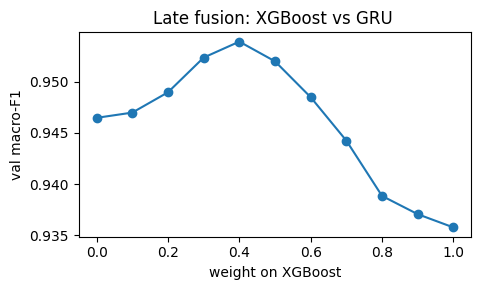

In [11]:
rnn_names = [n for n in PROBS if not n.startswith("XGBoost")]
best_rnn = max(rnn_names, key=lambda n: f1_score(y[VA], PROBS[n][0].argmax(1), average="macro"))
px_va, px_te = PROBS["XGBoost · roll3 (ours, 32)"]
pr_va, pr_te = PROBS[best_rnn]
ws = np.round(np.arange(0, 1.01, 0.1), 1)
val_f1 = [f1_score(y[VA], (w * px_va + (1 - w) * pr_va).argmax(1), average="macro") for w in ws]
W = float(ws[int(np.argmax(val_f1))])
fused = metrics(y[TE], W * px_te + (1 - W) * pr_te, H_TE)
C = pd.DataFrame({"XGBoost roll3 (ours)": metrics(y[TE], px_te, H_TE), best_rnn: metrics(y[TE], pr_te, H_TE),
                  f"fusion (w_xgb={W})": fused}).T[SHOW].round(3)
print(f"best RNN on val: {best_rnn} | fusion weight for XGBoost chosen on val: {W}"); display(C)
with tracking.run("Fusion · XGBoost + best RNN", params={"rnn": best_rnn, "w_xgb": W}, tags={"stage": "dl_ablation", "part": "C"}):
    tracking.log_metrics(fused)
plt.figure(figsize=(5, 3)); plt.plot(ws, val_f1, marker="o"); plt.xlabel("weight on XGBoost"); plt.ylabel("val macro-F1")
plt.title("Late fusion: XGBoost vs " + best_rnn.split("·")[0]); plt.tight_layout(); plt.savefig(REP / "fusion_weight.png"); plt.show()

## 6 · Summary and save

In [12]:
print("Part A — window level, split_run test, mean ± std over seeds (train_s = training seconds, ms_per_1k = CPU inference per 1,000 windows):")
display(A_TABLE)
print("Part B — packet-event BiLSTM vs XGBoost on the same covered test windows:"); display(B[SHOW].round(3))
print("Part C — fusion:"); display(C)

A.to_csv(REP / "partA_window_history.csv", index=False, encoding="utf-8-sig"); A_TABLE.to_csv(REP / "partA_summary.csv", encoding="utf-8-sig")
B.to_csv(REP / "partB_packet_bilstm.csv", encoding="utf-8-sig"); C.to_csv(REP / "partC_fusion.csv", encoding="utf-8-sig")
with tracking.run("DL ablation summary", tags={"stage": "dl_ablation_summary"}):
    tracking.log_files(REP / "partA_summary.csv", REP / "partB_packet_bilstm.csv", REP / "partC_fusion.csv", REP / "fusion_weight.png")
print("saved to", REP)

Part A — window level, split_run test, mean ± std over seeds (train_s = training seconds, ms_per_1k = CPU inference per 1,000 windows):


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h,train_s,ms_per_1k
model,,,,,,,
XGBoost · no memory (27),0.896 ± 0.002,0.878 ± 0.002,0.756 ± 0.005,0.68 ± 0.007,4.445 ± 0.064,5.851 ± 0.963,5.81 ± 1.084
"XGBoost · roll3 (ours, 32)",0.928 ± 0.001,0.916 ± 0.001,0.772 ± 0.003,0.8 ± 0.004,1.293 ± 0.043,7.732 ± 1.109,7.996 ± 1.701
XGBoost · roll10 (27+10),0.923 ± 0.001,0.911 ± 0.001,0.736 ± 0.004,0.818 ± 0.001,2.437 ± 0.058,6.26 ± 0.508,7.09 ± 1.878
LSTM · window history N=1,0.888 ± 0.002,0.869 ± 0.003,0.719 ± 0.01,0.658 ± 0.015,4.194 ± 1.193,10.82 ± 2.478,1.34 ± 0.143
LSTM · window history N=3,0.941 ± 0.006,0.931 ± 0.006,0.817 ± 0.022,0.829 ± 0.014,1.665 ± 0.268,8.745 ± 2.003,2.64 ± 0.122
LSTM · window history N=10,0.942 ± 0.004,0.933 ± 0.004,0.8 ± 0.024,0.853 ± 0.015,2.185 ± 0.301,43.299 ± 22.1,37.767 ± 46.741
GRU · window history N=10,0.943 ± 0.003,0.933 ± 0.004,0.807 ± 0.012,0.845 ± 0.012,1.962 ± 0.534,162.621 ± 67.131,46.005 ± 4.969


Part B — packet-event BiLSTM vs XGBoost on the same covered test windows:


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
model,,,,,
XGBoost · roll3 (ours) on covered windows,0.944,0.934,0.809,0.877,0.385
"BiLSTM packet events (seed 0, window-level)",0.891,0.874,0.658,0.760,6.138


Part C — fusion:


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
XGBoost roll3 (ours),0.930,0.918,0.775,0.810,1.172
GRU · window history N=10,0.945,0.936,0.814,0.849,1.813
fusion (w_xgb=0.4),0.951,0.943,0.830,0.867,1.032


saved to c:\Users\rashi\Desktop\VitalGate Project Code\reports\dl_ablation


## How to read it
* **N = 10 vs N = 1 (LSTM):** the gain from learned memory. **XGBoost roll3 vs no memory:** the gain from engineered memory. If both gains are similar, the rolling features already capture what the LSTM learns.
* **LSTM N = 10 vs XGBoost roll10:** same memory length, learned vs engineered — the fairest head-to-head.
* **Packet BiLSTM vs XGBoost on covered windows:** does packet order add anything over window statistics? Watch ransomware and exfiltration.
* **Fusion:** if the fused model clearly beats XGBoost (≥ ~0.005 macro-F1 or fewer false alarms), the LSTM carries complementary information → consider it for the final model; otherwise XGBoost alone is the better engineering choice (exact SHAP, cheap federation, faster CPU inference).

In [13]:
# Fairness check: give XGBoost the same history the LSTM sees (all 27 features + time gaps)
f = d.sort_values(["split_run", "client_ip", "window_start"])
g = f.groupby(["split_run", "client_ip"], sort=False)
extra = pd.DataFrame(index=f.index)
extra["gap_s"] = g["window_start"].diff().clip(0, 3600)                       # NaN at a host's first window (XGBoost handles NaN)
extra["gap_lag1"] = extra.groupby([f["split_run"], f["client_ip"]], sort=False)["gap_s"].shift(1)
for L in (1, 2):
    sh = g[BASE27].shift(L); sh.columns = [f"{c}_lag{L}" for c in BASE27]; extra = extra.join(sh)
r3 = g[BASE27].rolling(3, min_periods=1).mean().reset_index(level=[0, 1], drop=True)
r3.columns = [f"{c}_r3all" for c in BASE27]; extra = extra.join(r3)
D2 = pd.concat([d, extra.sort_index()], axis=1)
GAP = ["gap_s", "gap_lag1"]; LAGS = [c for c in extra if "_lag" in c and c != "gap_lag1"]; R3ALL = list(r3.columns)

FAIR = {"XGBoost · roll3 + time gap": FEATURES + GAP,
        "XGBoost · lag1-2 of all 27 + gap": BASE27 + LAGS + GAP,
        "XGBoost · roll3 of all 27 + gap": BASE27 + R3ALL + GAP,
        "XGBoost · lags + roll3 all + gap": BASE27 + LAGS + R3ALL + GAP}
fair_rows = []
for name, cols in FAIR.items():
    with tracking.run(name, params={"n_features": len(cols)}, tags={"stage": "dl_ablation", "part": "A_fair"}):
        pv, ps = [], []
        for s in SEEDS:
            t0 = time.time(); m = fit_xgb(D2.loc[TR, cols], y[TR], D2.loc[VA, cols], y[VA], s); tr_s = time.time() - t0
            t0 = time.time(); p = m.predict_proba(D2.loc[TE, cols]); ms = (time.time() - t0) / TE.sum() * 1e6
            ps.append(p); pv.append(m.predict_proba(D2.loc[VA, cols]))
            fair_rows.append(dict(model=name, seed=s, train_s=tr_s, ms_per_1k=ms, **metrics(y[TE], p, H_TE)))
        tracking.log_seed_summary([{k: v for k, v in r.items() if k not in ("model", "seed")} for r in fair_rows if r["model"] == name])
        PROBS[name] = (np.mean(pv, 0), np.mean(ps, 0))
    print(name, "done")
FAIR_TABLE = summarise(fair_rows)
display(pd.concat([A_TABLE.loc[["XGBoost · roll3 (ours, 32)", "LSTM · window history N=3", "GRU · window history N=10"]], FAIR_TABLE]))

# best fair XGBoost + GRU fusion, weight chosen on val
best_fair = max(FAIR, key=lambda n: f1_score(y[VA], PROBS[n][0].argmax(1), average="macro"))
pxv, pxt = PROBS[best_fair]; pgv, pgt = PROBS["GRU · window history N=10"]
wf = [f1_score(y[VA], (w * pxv + (1 - w) * pgv).argmax(1), average="macro") for w in ws]; Wf = float(ws[int(np.argmax(wf))])
display(pd.DataFrame({best_fair: metrics(y[TE], pxt, H_TE), f"fusion {best_fair} + GRU (w={Wf})": metrics(y[TE], Wf * pxt + (1 - Wf) * pgt, H_TE)}).T[SHOW].round(3))
FAIR_TABLE.to_csv(REP / "partA_fair_xgb.csv", encoding="utf-8-sig")

XGBoost · roll3 + time gap done
XGBoost · lag1-2 of all 27 + gap done
XGBoost · roll3 of all 27 + gap done
XGBoost · lags + roll3 all + gap done


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h,train_s,ms_per_1k
model,,,,,,,
"XGBoost · roll3 (ours, 32)",0.928 ± 0.001,0.916 ± 0.001,0.772 ± 0.003,0.8 ± 0.004,1.293 ± 0.043,7.732 ± 1.109,7.996 ± 1.701
LSTM · window history N=3,0.941 ± 0.006,0.931 ± 0.006,0.817 ± 0.022,0.829 ± 0.014,1.665 ± 0.268,8.745 ± 2.003,2.64 ± 0.122
GRU · window history N=10,0.943 ± 0.003,0.933 ± 0.004,0.807 ± 0.012,0.845 ± 0.012,1.962 ± 0.534,162.621 ± 67.131,46.005 ± 4.969
XGBoost · roll3 + time gap,0.931 ± 0.002,0.92 ± 0.002,0.777 ± 0.004,0.819 ± 0.005,0.995 ± 0.016,7.906 ± 1.325,6.983 ± 0.43
XGBoost · lag1-2 of all 27 + gap,0.956 ± 0.001,0.948 ± 0.001,0.841 ± 0.002,0.886 ± 0.005,0.493 ± 0.043,13.277 ± 0.444,8.138 ± 1.075
XGBoost · roll3 of all 27 + gap,0.955 ± 0.001,0.948 ± 0.001,0.843 ± 0.003,0.877 ± 0.002,0.632 ± 0.07,11.301 ± 0.256,8.414 ± 0.791
XGBoost · lags + roll3 all + gap,0.956 ± 0.002,0.948 ± 0.002,0.845 ± 0.005,0.879 ± 0.009,0.586 ± 0.074,19.17 ± 1.827,8.596 ± 0.762


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
XGBoost · lag1-2 of all 27 + gap,0.954,0.947,0.836,0.883,0.502
fusion XGBoost · lag1-2 of all 27 + gap + GRU (w=0.6),0.960,0.954,0.860,0.897,0.586


### Transformer model testing against baseline

In [15]:
# === Transformer baseline vs XGBoost v3 (last N windows per host) ===
import sys, numpy as np, pandas as pd, torch, torch.nn as nn
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO)); from src import features as FV

LABEL   = "label_class"                 # <- change if your attack-class column has another name
EXCLUDE = ["preamble_polyglot"]   # rule class, not ML
N, SEEDS, EPOCHS, PATIENCE, BS = 10, [0, 1, 2], 40, 6, 512
DEV = "cuda" if torch.cuda.is_available() else "cpu"

# ---- data: same base features + gap as XGBoost v3 ----
win = FV.add_base(pd.read_parquet(REPO / "data/processed/windows_v2.parquet"))
win = win[~win[LABEL].isin(EXCLUDE)].reset_index(drop=True)
d   = FV.add_history(win, "split_run")                     # gives gap_s, original row order
classes = sorted(d[LABEL].unique()); cid = {c: i for i, c in enumerate(classes)}
y   = d[LABEL].map(cid).values
tr, va, te = [(d.split_run == s).values for s in ("train", "val", "test")]

F  = FV.BASE27
sc = StandardScaler().fit(d.loc[tr, F].fillna(0))
gap = (np.log1p(d["gap_s"].fillna(3600).values) / np.log1p(3600))[:, None]
Z  = np.vstack([np.hstack([sc.transform(d[F].fillna(0)), gap]), np.zeros((1, len(F) + 1))]).astype("float32")
PAD = len(d)                                               # last row of Z = padding

# ---- index of last N windows per (split, host), oldest -> current ----
idx = np.full((len(d), N), PAD, dtype=np.int64)
o = d.sort_values(["split_run", "client_ip", "window_start"], kind="stable")
for _, pos in o.groupby(["split_run", "client_ip"], sort=False).indices.items():
    rows = o.index.values[pos]
    for k in range(min(N, len(rows))):
        idx[rows[k:], N - 1 - k] = rows[:len(rows) - k]
Zt, It, yt = torch.tensor(Z), torch.tensor(idx), torch.tensor(y)

class TFM(nn.Module):
    def __init__(s, f, dm=64, heads=4, layers=2, c=len(classes)):
        super().__init__()
        s.inp = nn.Linear(f, dm); s.pos = nn.Parameter(torch.zeros(1, N, dm))
        s.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(dm, heads, 128, 0.1, batch_first=True), layers)
        s.out = nn.Linear(dm, c)
    def forward(s, i):
        x, m = Zt[i].to(DEV), (i == PAD).to(DEV)
        return s.out(s.enc(s.inp(x) + s.pos, src_key_padding_mask=m)[:, -1])   # current window

def predict(model, rows):
    model.eval(); out = []
    with torch.no_grad():
        for b in range(0, len(rows), 4096):
            out.append(model(It[rows[b:b + 4096]]).argmax(1).cpu())
    return torch.cat(out).numpy()

cnt = np.bincount(y[tr], minlength=len(classes))
w = torch.tensor(np.sqrt(cnt.max() / cnt), dtype=torch.float32, device=DEV)   # sqrt weights, like XGBoost
TR, VA, TE = (np.where(m)[0] for m in (tr, va, te))
no_recon = [i for c, i in cid.items() if c != "recon"]

res = []
for seed in SEEDS:
    torch.manual_seed(seed); np.random.seed(seed)
    model = TFM(Z.shape[1]).to(DEV); opt = torch.optim.AdamW(model.parameters(), 1e-3, weight_decay=1e-4)
    lossf = nn.CrossEntropyLoss(weight=w); best, bad, state = -1, 0, None
    for ep in range(EPOCHS):
        model.train(); perm = np.random.permutation(TR)
        for b in range(0, len(perm), BS):
            r = perm[b:b + BS]; opt.zero_grad()
            lossf(model(It[r]), yt[r].to(DEV)).backward(); opt.step()
        f = f1_score(y[VA], predict(model, VA), average="macro")
        if f > best: best, bad, state = f, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(state); p = predict(model, TE)
    pc = f1_score(y[TE], p, average=None, labels=range(len(classes)))
    res.append(dict(seed=seed, macro_f1=f1_score(y[TE], p, average="macro"),
                    macro_f1_no_recon=f1_score(y[TE], p, average="macro", labels=no_recon),
                    exfil_f1=pc[cid["exfiltration"]], ransom_f1=pc[cid["ransomware_like"]], epochs=ep + 1))
    print(res[-1])

R = pd.DataFrame(res)
print(f"\nTransformer N={N}: macro-F1 {R.macro_f1.mean():.3f} ± {R.macro_f1.std():.3f} | "
      f"exfil {R.exfil_f1.mean():.3f} | ransom {R.ransom_f1.mean():.3f}")
print("Reference: XGBoost v3 0.956 (exfil 0.841, ransom 0.886) | GRU 0.943 | LSTM N=10 0.942")

{'seed': 0, 'macro_f1': 0.9275811037972305, 'macro_f1_no_recon': 0.9169118479875252, 'exfil_f1': np.float64(0.7585034013605442), 'ransom_f1': np.float64(0.8195121951219512), 'epochs': 26}
{'seed': 1, 'macro_f1': 0.9340697163211505, 'macro_f1_no_recon': 0.9238806962195997, 'exfil_f1': np.float64(0.7768595041322314), 'ransom_f1': np.float64(0.8415446071904128), 'epochs': 21}
{'seed': 2, 'macro_f1': 0.934420167043073, 'macro_f1_no_recon': 0.9244930027455988, 'exfil_f1': np.float64(0.7896551724137931), 'ransom_f1': np.float64(0.8345498783454988), 'epochs': 27}

Transformer N=10: macro-F1 0.932 ± 0.004 | exfil 0.775 | ransom 0.832
Reference: XGBoost v3 0.956 (exfil 0.841, ransom 0.886) | GRU 0.943 | LSTM N=10 0.942
